# BAMM — Bouclier Anti-fraude Mobile Money
### Pipeline Data Science : détection d'appels frauduleux (vishing) au Bénin

**Hackathon AI4Youth 2026 · Défi Cybersécurité** — Expedit AHITCHEME · Esmeralda AKANRO · Khaled BACHAROU · Antonella TAMADAHO

**Problème.** Au Bénin, la fraude mobile money passe surtout par le *vishing* (un faux agent MTN/Moov appelle et
réclame le code PIN/OTP) et par la *manipulation USSD* (le fraudeur dicte un code de transfert du type `*880*7721*45000#`
présenté comme une « mise à jour »).

**Objectif de ce notebook.** Construire, évaluer et interpréter un modèle de **classification binaire**
(appel frauduleux / légitime), puis l'exporter en **TensorFlow Lite** pour l'application Android BAMM
(inférence hors ligne sur le téléphone).

| Section | Contenu |
|---|---|
| 1 | Construction du dataset synthétique documenté |
| 2 | Analyse exploratoire (EDA) |
| 3 | Prétraitement |
| 4 | Modélisation comparative : Régression logistique, Random Forest, XGBoost, MLP |
| 5 | Évaluation comparative (Recall en priorité) |
| 6 | Interprétabilité : importance des variables, SHAP, succès/échecs |
| 7 | Export TFLite pour l'app Android (modèle complet + modèle « avant décroché ») |
| 8 | Limites et pistes d'amélioration |

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # accès au package `bamm`

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import tensorflow as tf, shap

from bamm import dataset, features as F, modeling as M

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid", palette=["#1f7a4d", "#d64545"])
DATA, MODELS, FIG = Path("../data"), Path("../models"), Path("../reports/figures")
for d in (DATA, MODELS, FIG): d.mkdir(parents=True, exist_ok=True)
print("TensorFlow", tf.__version__, "| SHAP", shap.__version__)

TensorFlow 2.21.0 | SHAP 0.54.1


## 1. Construction du dataset

Il n'existe **aucun dataset public** d'appels frauduleux mobile money au Bénin. Nous générons donc un dataset
synthétique de **10 000 appels**, reproductible (graine 42), dont chaque distribution est explicitement paramétrée
(module `bamm/dataset.py`) et justifiée ci-dessous à partir des rapports publics (GSMA 2025, TechNext24,
MTN Bénin, presse béninoise).

| Feature | Type | Fraude | Légitime | Justification |
|---|---|---|---|---|
| `caller_id` | str | hash | hash | identifiant anonymisé — **exclu** du modèle |
| `call_hour` | int 0-23 | 65 % ~ 𝒩(12 h, 1,8 h), 35 % uniforme 7-21 h | ~ 𝒩(14 h, 3,8 h) + 7 % de nuit | fraudes concentrées aux heures de marché |
| `call_duration_sec` | int | Gamma (≈ 60-300 s), 12 % < 60 s (victime qui raccroche) | log-normale, médiane ≈ 74 s | il faut 1 à 5 min pour convaincre |
| `n_reports` | int | 50 % numéros **neufs** (0), sinon 1 + BinNég (moy. ≈ 12) | 0, sauf 5 % de faux signalements (1-2) | base communautaire |
| `call_frequency_7d` | int | 55 % rafales 50-200, 45 % prudents 2-50 | 1 + BinNég (moy. ≈ 9), 10 % commerçants 40-160, officiels 150-600 | les fraudeurs appellent en masse |
| `is_registered_operator` | bool | 0,4 % (usurpation d'identifiant) | 5 % | whitelist MTN/Moov |
| `region` | cat. (12 départements) | sur-représentée Littoral/Atlantique/Ouémé | ~ démographie | densité mobile money urbaine |
| `ussd_after_call` | bool | 45 % | 6 % | USSD de transfert < 5 min après l'appel |
| `is_fraud` | bool | **≈ 15 %** | ≈ 85 % | déséquilibre réaliste |

**Recouvrements volontaires** : fraudeurs neufs sans signalement, fraudeurs « prudents » à faible fréquence,
commerçants légitimes qui appellent beaucoup, transferts légitimes après un appel familial, faux signalements.
Sans cela le problème serait trivial et le modèle n'apprendrait rien d'utile.

In [2]:
print(json.dumps(dataset.PARAMS, indent=1))
df = dataset.generate(seed=SEED)
df.to_csv(DATA / "bamm_calls.csv", index=False)
print(df.shape); df.head()

{
 "n_records": 10000,
 "fraud_rate": 0.15,
 "fraud_hour_peak_share": 0.65,
 "fraud_hour_mu": 12.0,
 "fraud_hour_sigma": 1.8,
 "fraud_short_call_share": 0.12,
 "legit_duration_lognorm": [
  4.3,
  0.9
 ],
 "fraud_new_number_share": 0.5,
 "fraud_reports_nb": [
  1.2,
  0.09
 ],
 "legit_false_report_share": 0.05,
 "fraud_burst_share": 0.55,
 "legit_business_share": 0.1,
 "legit_official_share": 0.05,
 "fraud_spoof_official_share": 0.004,
 "fraud_ussd_share": 0.45,
 "legit_ussd_share": 0.06
}
(10000, 9)


,caller_id,call_hour,call_duration_sec,n_reports,call_frequency_7d,is_registered_operator,region,ussd_after_call,is_fraud
0,905b2cbceba6,14,107,0,9,False,Alibori,False,False
1,37c16ce25a02,10,48,0,7,False,Littoral,False,False
2,2e91d49c9d01,3,41,0,2,False,Couffo,False,False
3,012d69721c42,23,54,0,108,False,Littoral,False,False
4,32a2d5212a47,16,232,0,116,False,Atlantique,False,True


In [3]:
df.info()
print("\nValeurs manquantes :", int(df.isna().sum().sum()), "| doublons de caller_id :", int(df.caller_id.duplicated().sum()))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   caller_id               10000 non-null  str  
 1   call_hour               10000 non-null  int64
 2   call_duration_sec       10000 non-null  int64
 3   n_reports               10000 non-null  int64
 4   call_frequency_7d       10000 non-null  int64
 5   is_registered_operator  10000 non-null  bool 
 6   region                  10000 non-null  str  
 7   ussd_after_call         10000 non-null  bool 
 8   is_fraud                10000 non-null  bool 
dtypes: bool(3), int64(4), str(2)
memory usage: 498.2 KB

Valeurs manquantes : 0 | doublons de caller_id : 0


,count,mean,std,min,25%,50%,75%,max
call_hour,10000.0,13.7714,4.014767,0.0,11.0,14.0,16.0,23.0
call_duration_sec,10000.0,118.8348,119.931611,3.0,43.0,83.0,161.0,1800.0
n_reports,10000.0,1.0413,4.687770,0.0,0.0,0.0,0.0,75.0
call_frequency_7d,10000.0,42.6222,85.592632,1.0,5.0,10.0,27.0,599.0


## 2. Analyse exploratoire (EDA)
### 2.1 Variable cible et déséquilibre

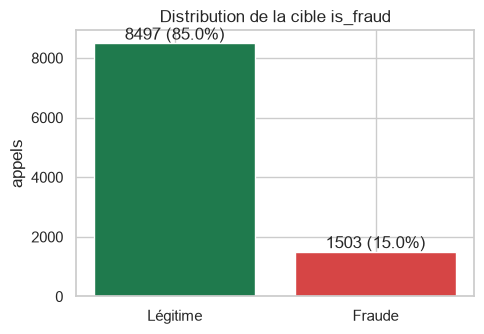

In [4]:
counts = df.is_fraud.value_counts().rename({False: "Légitime", True: "Fraude"})
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#1f7a4d", "#d64545"])
ax.bar_label(bars, labels=[f"{v} ({v/len(df):.1%})" for v in counts.values])
ax.set_title("Distribution de la cible is_fraud"); ax.set_ylabel("appels")
plt.tight_layout(); plt.savefig(FIG / "01_target.png", dpi=120); plt.show()

Le ratio ≈ 15/85 est **déséquilibré** : un modèle qui prédit toujours « légitime » aurait 85 % d'accuracy et
un recall nul. Stratégie : (1) `class_weight='balanced'` / `scale_pos_weight` pour tous les modèles, (2) comparaison
avec **SMOTE** sur la régression logistique, (3) métriques centrées sur la classe fraude (Recall, F1, F2, AUC).

### 2.2 Distributions par classe

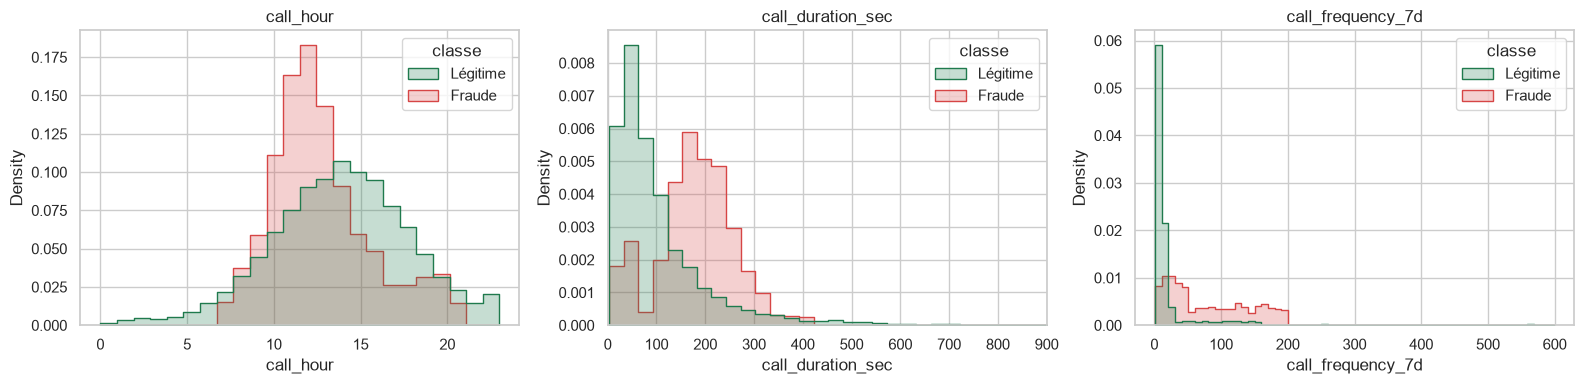

In [5]:
lab = df.is_fraud.map({False: "Légitime", True: "Fraude"}).rename("classe")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, bins in zip(axes, ["call_hour", "call_duration_sec", "call_frequency_7d"], [24, 60, 60]):
    sns.histplot(df.assign(classe=lab), x=col, hue="classe", bins=bins, stat="density",
                 common_norm=False, element="step", ax=ax, palette=["#1f7a4d", "#d64545"])
    ax.set_title(col)
axes[1].set_xlim(0, 900)
plt.tight_layout(); plt.savefig(FIG / "02_histograms.png", dpi=120); plt.show()

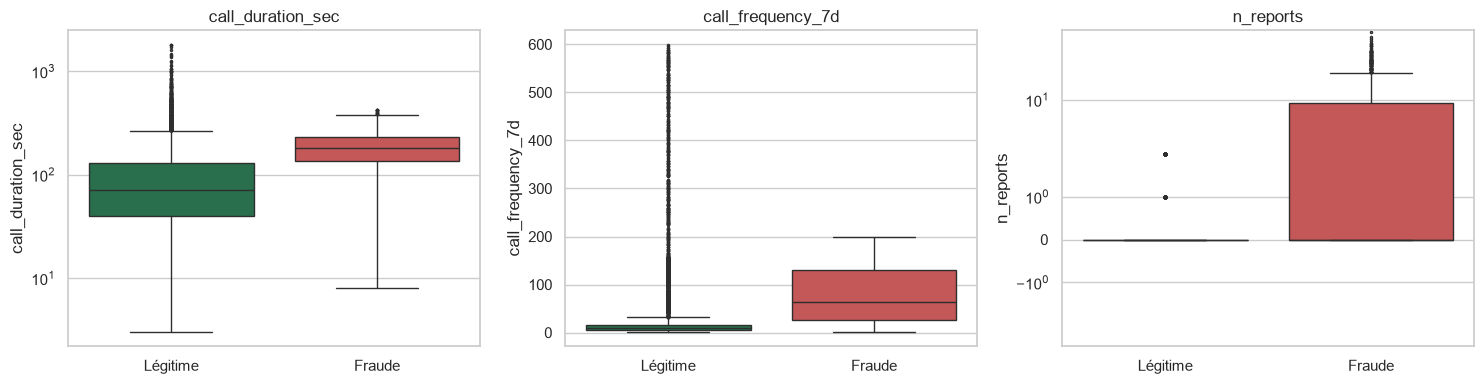

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["call_duration_sec", "call_frequency_7d", "n_reports"]):
    sns.boxplot(x=lab, y=df[col], ax=ax, palette=["#1f7a4d", "#d64545"], showfliers=True, fliersize=1.5)
    ax.set_title(col); ax.set_xlabel("")
axes[0].set_yscale("log"); axes[2].set_yscale("symlog")
plt.tight_layout(); plt.savefig(FIG / "03_boxplots.png", dpi=120); plt.show()

### 2.3 Corrélations

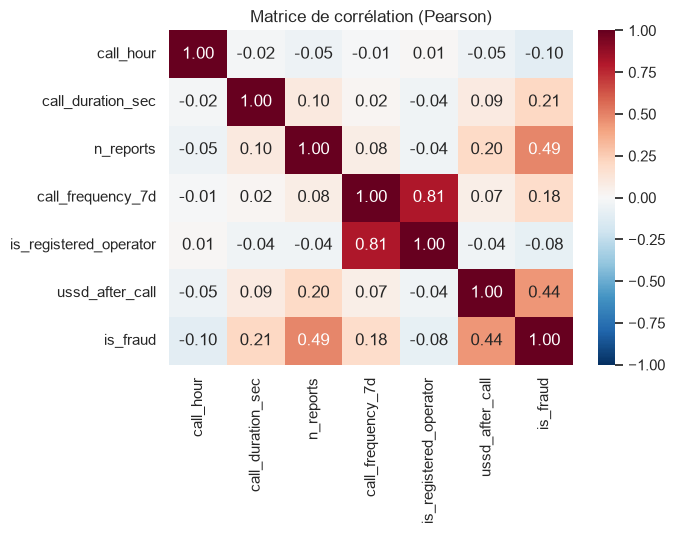

In [7]:
num = df.drop(columns=["caller_id", "region"]).astype(float)
plt.figure(figsize=(7, 5.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation (Pearson)")
plt.tight_layout(); plt.savefig(FIG / "04_correlation.png", dpi=120); plt.show()

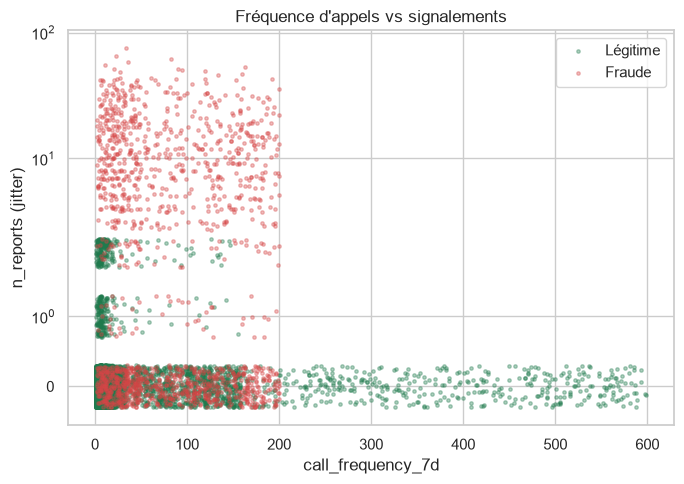

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for v, c, name in [(False, "#1f7a4d", "Légitime"), (True, "#d64545", "Fraude")]:
    s = df[df.is_fraud == v]
    ax.scatter(s.call_frequency_7d, s.n_reports + np.random.uniform(-.3, .3, len(s)), s=6, alpha=.35, c=c, label=name)
ax.set_xlabel("call_frequency_7d"); ax.set_ylabel("n_reports (jitter)"); ax.set_yscale("symlog"); ax.legend()
ax.set_title("Fréquence d'appels vs signalements")
plt.tight_layout(); plt.savefig(FIG / "05_scatter.png", dpi=120); plt.show()

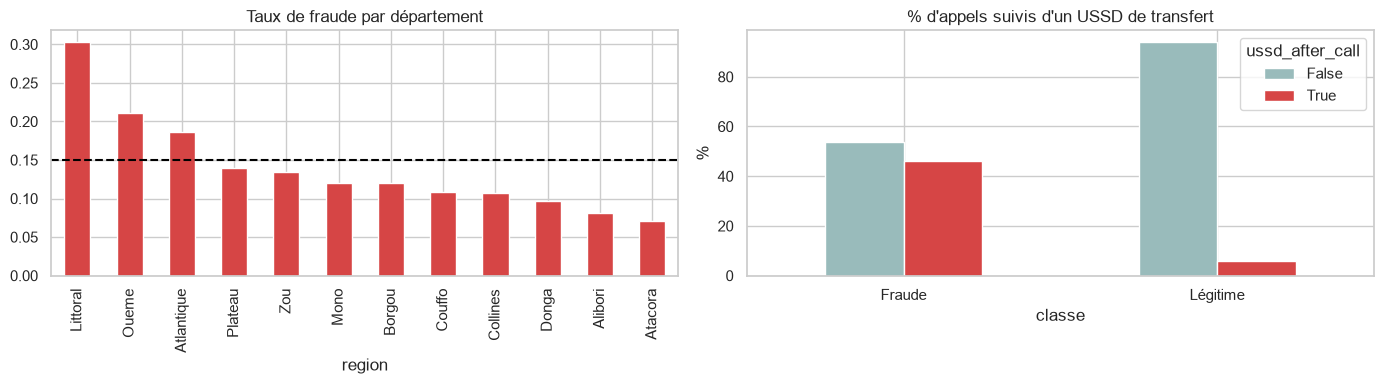

,mean,size
region,,
Littoral,0.302895,898
Oueme,0.210482,1183
Atlantique,0.186485,1539
Plateau,0.139116,611
Zou,0.133820,822
Mono,0.120332,482
Borgou,0.119820,1110
Couffo,0.108029,685
Collines,0.107198,653


In [9]:
reg = df.groupby("region").is_fraud.agg(["mean", "size"]).sort_values("mean", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
reg["mean"].plot.bar(ax=axes[0], color="#d64545"); axes[0].set_title("Taux de fraude par département"); axes[0].axhline(df.is_fraud.mean(), ls="--", c="k")
(pd.crosstab(lab, df.ussd_after_call, normalize="index") * 100).plot.bar(ax=axes[1], color=["#9bb", "#d64545"])
axes[1].set_title("% d'appels suivis d'un USSD de transfert"); axes[1].set_ylabel("%"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "06_region_ussd.png", dpi=120); plt.show()
reg

### 2.4 Synthèse de l'EDA
- **`n_reports`** et **`call_frequency_7d`** sont les variables les plus discriminantes, mais **aucune ne suffit seule** :
  la moitié des fraudeurs ont un numéro neuf (0 signalement) et des commerçants légitimes appellent en rafale.
- **`call_hour`** : pic de fraude 10 h-14 h (heures de marché) ; les appels légitimes sont plus étalés.
- **`call_duration_sec`** : les fraudes se situent majoritairement entre 1 et 5 min ; les appels légitimes ont une longue traîne.
- **`ussd_after_call`** : signal fort (45 % vs 6 %) mais **disponible seulement après l'appel**.
- **`region`** : effet modéré (zones urbaines plus touchées) → risque de **biais régional**, à surveiller (section 8).
- Corrélations linéaires modérées entre features → pas de multicolinéarité problématique.

## 3. Prétraitement

| Choix | Justification |
|---|---|
| Suppression de `caller_id` | identifiant, aucun pouvoir prédictif généralisable (fuite si conservé) |
| One-Hot sur `region` (12 catégories **fixes**) | variable nominale sans ordre ; catégories figées pour que l'app Android encode à l'identique |
| `StandardScaler` sur les numériques | indispensable pour la régression logistique et le MLP ; sans effet sur les arbres |
| Booléens en 0/1 | — |
| Split **70/15/15 stratifié** sur `is_fraud` | conserve le ratio 15/85 dans chaque jeu ; la validation sert au réglage du seuil, le test n'est utilisé qu'une fois |

Le scaler est **ajusté sur le train uniquement** (pas de fuite d'information). Pour le MLP il est intégré au
graphe Keras (couche `Normalization`) afin que le `.tflite` accepte directement des valeurs brutes.

In [10]:
SPEC = F.FULL
NAMES = F.feature_names(SPEC)
X = F.encode(df, SPEC); y = df.is_fraud.to_numpy(dtype=int)
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=y[i_tmp], random_state=SEED)
X_tr, X_va, X_te, y_tr, y_va, y_te = X[i_tr], X[i_va], X[i_te], y[i_tr], y[i_va], y[i_te]
K = len(SPEC["numeric"])
scaler = ColumnTransformer([("num", StandardScaler(), list(range(K)))], remainder="passthrough")
print("features :", NAMES)
for n_, yy in [("train", y_tr), ("validation", y_va), ("test", y_te)]:
    print(f"{n_:>10} : {len(yy):5d} appels, {yy.sum():4d} fraudes ({yy.mean():.1%})")

features : ['call_hour', 'call_duration_sec', 'n_reports', 'call_frequency_7d', 'is_registered_operator', 'ussd_after_call', 'region_Alibori', 'region_Atacora', 'region_Atlantique', 'region_Borgou', 'region_Collines', 'region_Couffo', 'region_Donga', 'region_Littoral', 'region_Mono', 'region_Oueme', 'region_Plateau', 'region_Zou']
     train :  7000 appels, 1052 fraudes (15.0%)
validation :  1500 appels,  226 fraudes (15.1%)
      test :  1500 appels,  225 fraudes (15.0%)


## 4. Modélisation comparative

Validation croisée **5-fold stratifiée** sur le train et `GridSearchCV`. Critère d'optimisation : **F2-score**,
qui pondère le recall 2× plus que la precision — un faux négatif (fraudeur non détecté = argent perdu) coûte
bien plus cher qu'un faux positif (alerte de trop sur un appel légitime). Optimiser le recall seul pousserait
à tout classer « fraude ».

| Modèle | Rôle | Hyperparamètres explorés |
|---|---|---|
| Régression logistique | baseline interprétable | `C`, `class_weight='balanced'` ; variante SMOTE |
| Random Forest | robuste sur données tabulaires | `n_estimators`, `max_depth`, `min_samples_leaf`, `class_weight` |
| XGBoost | gradient boosting | `max_depth`, `learning_rate`, `n_estimators`, `scale_pos_weight` |
| MLP (Keras) | le deep learning apporte-t-il un gain ? exportable en TFLite | 2 couches denses, dropout, early stopping |

In [11]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
f2 = make_scorer(fbeta_score, beta=2)
SCORING = {"f2": f2, "recall": "recall", "precision": "precision", "roc_auc": "roc_auc"}
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

searches = {
    "Logistic Regression": (Pipeline([("sc", scaler), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "LogReg + SMOTE": (ImbPipeline([("sc", scaler), ("smote", SMOTE(random_state=SEED)), ("clf", LogisticRegression(max_iter=2000))]),
                       {"clf__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {"n_estimators": [200, 400], "max_depth": [6, 10, None], "min_samples_leaf": [1, 5],
                       "class_weight": ["balanced", "balanced_subsample"]}),
    "XGBoost": (XGBClassifier(random_state=SEED, eval_metric="logloss", n_jobs=-1, tree_method="hist"),
                {"max_depth": [3, 5], "learning_rate": [0.05, 0.1], "n_estimators": [200, 400],
                 "scale_pos_weight": [1, spw]}),
}
best, cv_rows = {}, []
for name, (est, grid) in searches.items():
    t = time.time()
    gs = GridSearchCV(est, grid, scoring=SCORING, refit="f2", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs.best_estimator_
    r = gs.cv_results_; i = gs.best_index_
    cv_rows.append({"modèle": name, **{f"cv_{m}": f"{r['mean_test_'+m][i]:.3f} ± {r['std_test_'+m][i]:.3f}" for m in SCORING},
                    "meilleurs params": gs.best_params_, "durée (s)": round(time.time() - t, 1)})
    print(f"{name:20s} F2 cv = {r['mean_test_f2'][i]:.3f}  {gs.best_params_}")

Logistic Regression  F2 cv = 0.778  {'clf__C': 1}


LogReg + SMOTE       F2 cv = 0.784  {'clf__C': 10}


Random Forest        F2 cv = 0.857  {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}


XGBoost              F2 cv = 0.872  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400, 'scale_pos_weight': np.float64(5.653992395437262)}


### MLP Keras
Architecture : `Normalization → Dense(32, relu) → Dropout → Dense(16, relu) → Dropout → Dense(1, sigmoid)`,
perte *binary cross-entropy* pondérée par classe, Adam, **early stopping** sur la perte de validation.
Petite recherche sur le dropout et le learning rate, évaluée en validation croisée 5-fold.

dropout=0.1 lr=0.001: F2 cv = 0.841


dropout=0.1 lr=0.003: F2 cv = 0.844


dropout=0.3 lr=0.001: F2 cv = 0.838


dropout=0.3 lr=0.003: F2 cv = 0.840


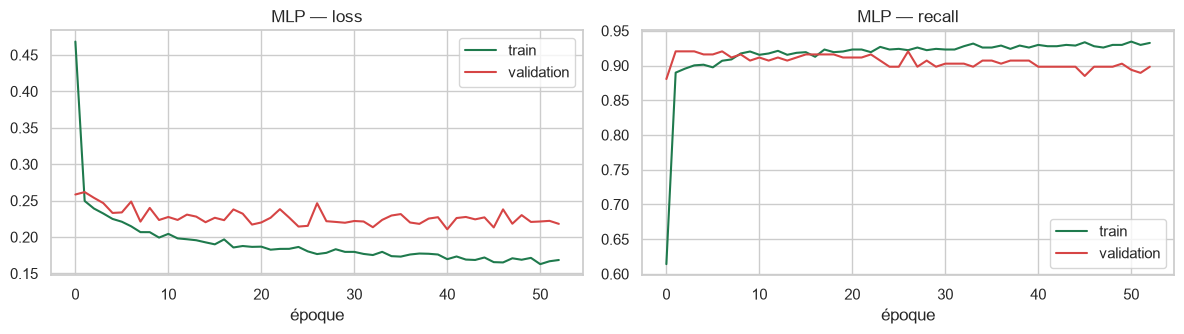

époques effectives : 53


In [12]:
mean_, var_ = F.scaler_stats(X_tr, SPEC)
def mlp_cv(dropout, lr):
    sc = {m: [] for m in SCORING}
    for tr, va in cv.split(X_tr, y_tr):
        mu, vv = F.scaler_stats(X_tr[tr], SPEC)
        m = M.build_mlp(X.shape[1], mu, vv, dropout=dropout, lr=lr)
        M.fit_mlp(m, X_tr[tr], y_tr[tr], X_tr[va], y_tr[va])
        p = m.predict(X_tr[va], verbose=0).ravel(); yhat = (p >= .5).astype(int)
        sc["f2"].append(fbeta_score(y_tr[va], yhat, beta=2)); sc["recall"].append(recall_score(y_tr[va], yhat))
        sc["precision"].append(precision_score(y_tr[va], yhat)); sc["roc_auc"].append(roc_auc_score(y_tr[va], p))
    return {k: (np.mean(v), np.std(v)) for k, v in sc.items()}

t = time.time(); mlp_grid = {}
for dropout in (0.1, 0.3):
    for lr in (1e-3, 3e-3):
        mlp_grid[(dropout, lr)] = mlp_cv(dropout, lr)
        print(f"dropout={dropout} lr={lr}: F2 cv = {mlp_grid[(dropout, lr)]['f2'][0]:.3f}")
bd, blr = max(mlp_grid, key=lambda k: mlp_grid[k]["f2"][0])
r = mlp_grid[(bd, blr)]
cv_rows.append({"modèle": "MLP (Keras)", **{f"cv_{m}": f"{r[m][0]:.3f} ± {r[m][1]:.3f}" for m in SCORING},
                "meilleurs params": {"dropout": bd, "lr": blr, "units": (32, 16)}, "durée (s)": round(time.time() - t, 1)})

mlp = M.build_mlp(X.shape[1], mean_, var_, dropout=bd, lr=blr)
hist = M.fit_mlp(mlp, X_tr, y_tr, X_va, y_va)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, k in zip(axes, ["loss", "recall"]):
    ax.plot(hist.history[k], label="train"); ax.plot(hist.history["val_" + k], label="validation")
    ax.set_title(f"MLP — {k}"); ax.set_xlabel("époque"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "07_mlp_curves.png", dpi=120); plt.show()
print("époques effectives :", len(hist.history["loss"]))

In [13]:
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(cv_rows).set_index("modèle")

,cv_f2,cv_recall,cv_precision,cv_roc_auc,meilleurs params,durée (s)
modèle,,,,,,
Logistic Regression,0.778 ± 0.014,0.837 ± 0.022,0.612 ± 0.038,0.947 ± 0.006,{'clf__C': 1},16.3
LogReg + SMOTE,0.784 ± 0.012,0.849 ± 0.021,0.603 ± 0.032,0.949 ± 0.006,{'clf__C': 10},3.4
Random Forest,0.857 ± 0.013,0.881 ± 0.017,0.774 ± 0.021,0.977 ± 0.004,"{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}",96.6
XGBoost,0.872 ± 0.013,0.912 ± 0.016,0.742 ± 0.011,0.981 ± 0.004,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400, 'scale_pos_weight': 5.653992395437262}",30.6
MLP (Keras),0.844 ± 0.016,0.896 ± 0.015,0.683 ± 0.024,0.971 ± 0.004,"{'dropout': 0.1, 'lr': 0.003, 'units': (32, 16)}",726.9


## 5. Évaluation comparative

Chaque modèle donne une probabilité. Le **seuil de décision** est réglé sur le jeu de **validation** (seuil qui
maximise le F2), puis toutes les métriques finales sont calculées **une seule fois** sur le jeu de **test**.

In [14]:
class KerasWrap:
    def __init__(s, m): s.m = m
    def predict_proba(s, X): p = s.m.predict(X, verbose=0).ravel(); return np.c_[1 - p, p]
models = {k: v for k, v in best.items()}; models["MLP (Keras)"] = KerasWrap(mlp)

def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    return float(ts[np.argmax([fbeta_score(y, (p >= t).astype(int), beta=2) for t in ts])])

rows, proba_te, thr = [], {}, {}
for name, m in models.items():
    thr[name] = best_threshold(y_va, m.predict_proba(X_va)[:, 1])
    p = m.predict_proba(X_te)[:, 1]; proba_te[name] = p; yh = (p >= thr[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, yh).ravel()
    rows.append({"modèle": name, "seuil": thr[name], "Accuracy": accuracy_score(y_te, yh), "Precision": precision_score(y_te, yh),
                 "Recall": recall_score(y_te, yh), "F1": f1_score(y_te, yh), "F2": fbeta_score(y_te, yh, beta=2),
                 "AUC-ROC": roc_auc_score(y_te, p), "fraudes ratées (FN)": fn, "fausses alertes (FP)": fp})
results = pd.DataFrame(rows).set_index("modèle").round(3)
results.to_csv(MODELS / "comparison_test.csv")
results.style.highlight_max(subset=["Recall", "F1", "F2", "AUC-ROC"], color="#c8ead6")

,seuil,Accuracy,Precision,Recall,F1,F2,AUC-ROC,fraudes ratées (FN),fausses alertes (FP)
modèle,,,,,,,,,
Logistic Regression,0.440000,0.886000,0.578000,0.893000,0.702000,0.805000,0.966000,24,147
LogReg + SMOTE,0.400000,0.877000,0.556000,0.907000,0.689000,0.805000,0.966000,21,163
Random Forest,0.440000,0.944000,0.749000,0.942000,0.835000,0.896000,0.983000,13,71
XGBoost,0.690000,0.961000,0.844000,0.911000,0.876000,0.897000,0.988000,20,38
MLP (Keras),0.640000,0.946000,0.773000,0.907000,0.834000,0.876000,0.981000,21,60


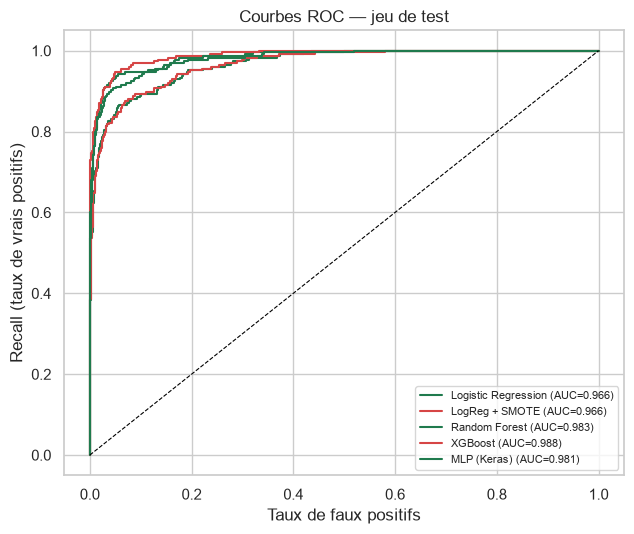

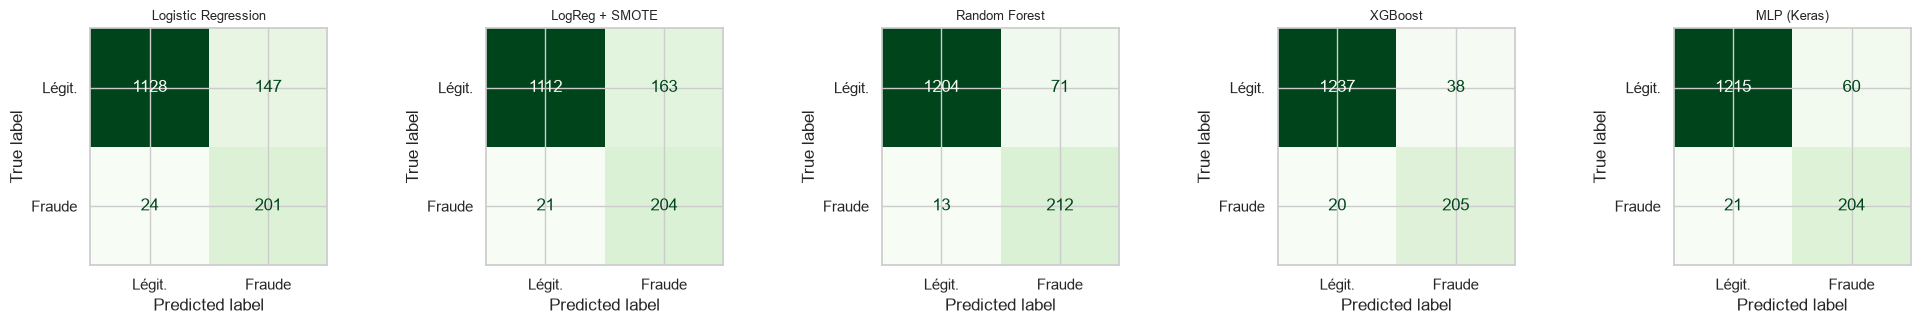

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, p in proba_te.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Recall (taux de vrais positifs)")
ax.set_title("Courbes ROC — jeu de test"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "08_roc.png", dpi=120); plt.show()

fig, axes = plt.subplots(1, len(proba_te), figsize=(4 * len(proba_te), 3.4))
for ax, (name, p) in zip(axes, proba_te.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, (p >= thr[name]).astype(int)), display_labels=["Légit.", "Fraude"]).plot(ax=ax, colorbar=False, cmap="Greens")
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "09_confusion.png", dpi=120); plt.show()

In [16]:
r = results
best_auc = r["AUC-ROC"].idxmax(); best_rec = r["Recall"].idxmax()
print(f"Meilleur AUC : {best_auc} ({r.loc[best_auc, 'AUC-ROC']:.3f}) | meilleur recall : {best_rec} ({r.loc[best_rec, 'Recall']:.3f})")
print(f"MLP : recall {r.loc['MLP (Keras)', 'Recall']:.1%}, precision {r.loc['MLP (Keras)', 'Precision']:.1%}, AUC {r.loc['MLP (Keras)', 'AUC-ROC']:.3f}")
gap = r["AUC-ROC"].max() - r.loc["MLP (Keras)", "AUC-ROC"]
print(f"Écart d'AUC entre le meilleur modèle et le MLP : {gap:.3f}")

Meilleur AUC : XGBoost (0.988) | meilleur recall : Random Forest (0.942)
MLP : recall 90.7%, precision 77.3%, AUC 0.981
Écart d'AUC entre le meilleur modèle et le MLP : 0.007


### Choix du modèle déployé
Les modèles non linéaires (Random Forest, XGBoost, MLP) dépassent nettement la baseline logistique ; entre eux les
écarts de recall/AUC sont faibles (voir le tableau ci-dessus). Le **MLP Keras** est retenu pour l'application car :

1. **Performance équivalente** aux meilleurs modèles d'arbres sur ce problème (écart d'AUC affiché ci-dessus) ;
2. **Export natif TensorFlow Lite** : le modèle évalué ici est *exactement* celui embarqué dans l'app (vérifié en
   section 7), sans conversion intermédiaire fragile (XGBoost → ONNX → TFLite) ;
3. **Taille de quelques Ko** et inférence < 1 ms → fonctionne **hors ligne** sur des téléphones d'entrée de gamme ;
4. le StandardScaler est **intégré au graphe**, ce qui supprime une source classique de bug de déploiement.

XGBoost reste la référence pour l'interprétabilité (TreeSHAP exact) et pour un éventuel scoring côté serveur.

## 6. Interprétabilité
### 6.1 Importance des variables (Random Forest, XGBoost)

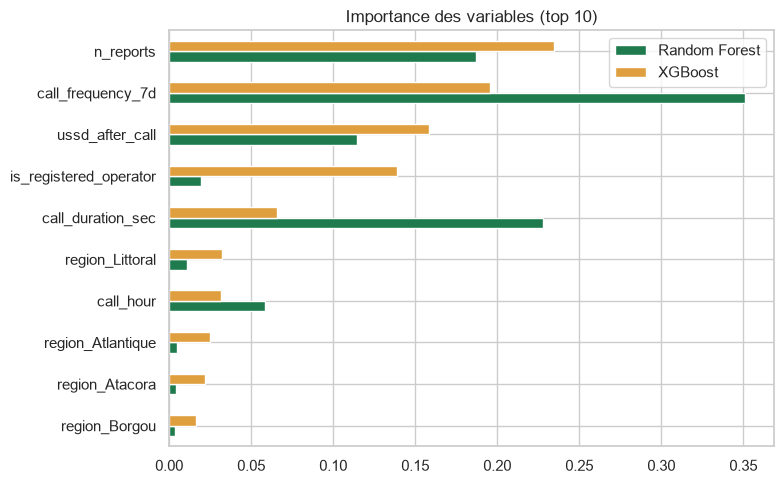

In [17]:
imp = pd.DataFrame({"Random Forest": best["Random Forest"].feature_importances_,
                    "XGBoost": best["XGBoost"].feature_importances_}, index=NAMES)
imp = imp.sort_values("XGBoost")
imp.tail(10).plot.barh(figsize=(8, 5), color=["#1f7a4d", "#e09f3e"]); plt.title("Importance des variables (top 10)")
plt.tight_layout(); plt.savefig(FIG / "10_importance.png", dpi=120); plt.show()

### 6.2 Valeurs SHAP du modèle retenu (MLP)
Explainer par permutation (agnostique au modèle) sur 300 appels de test, fond = 100 appels de train.

PermutationExplainer explainer:   2%|▏         | 5/300 [00:00<?, ?it/s]

PermutationExplainer explainer:   2%|▏         | 7/300 [00:13<04:32,  1.08it/s]

PermutationExplainer explainer:   3%|▎         | 8/300 [00:15<06:49,  1.40s/it]

PermutationExplainer explainer:   3%|▎         | 9/300 [00:17<08:32,  1.76s/it]

PermutationExplainer explainer:   3%|▎         | 10/300 [00:20<09:59,  2.07s/it]

...

PermutationExplainer explainer:  99%|█████████▉| 298/300 [12:09<00:04,  2.46s/it]

PermutationExplainer explainer: 100%|█████████▉| 299/300 [12:11<00:02,  2.32s/it]

PermutationExplainer explainer: 100%|██████████| 300/300 [12:13<00:00,  2.33s/it]

PermutationExplainer explainer: 301it [12:16,  2.40s/it]                         

PermutationExplainer explainer: 301it [12:16,  2.49s/it]

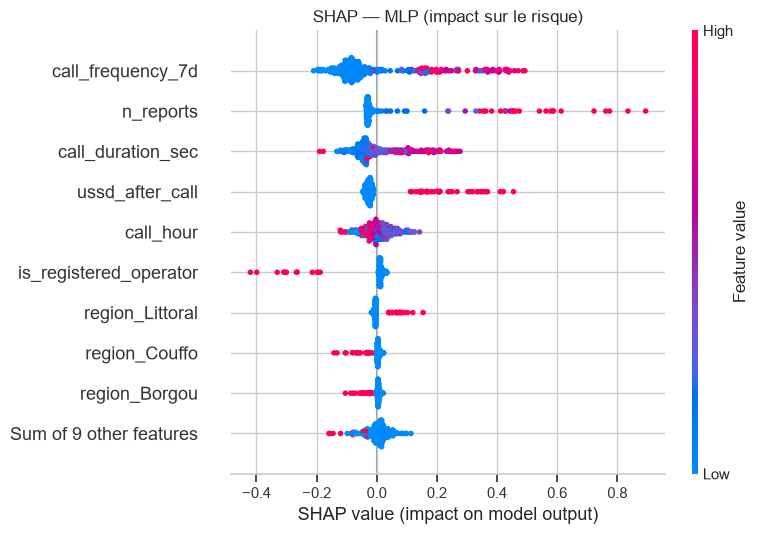

In [18]:
rng = np.random.default_rng(SEED)
bg = X_tr[rng.choice(len(X_tr), 100, replace=False)]
sample = X_te[rng.choice(len(X_te), 300, replace=False)]
f_mlp = lambda Z: mlp.predict(Z, verbose=0).ravel()
explainer = shap.Explainer(f_mlp, shap.maskers.Independent(bg), feature_names=NAMES, seed=SEED)
sv = explainer(sample)
shap.plots.beeswarm(sv, max_display=10, show=False); plt.title("SHAP — MLP (impact sur le risque)")
plt.tight_layout(); plt.savefig(FIG / "11_shap_beeswarm.png", dpi=120, bbox_inches="tight"); plt.show()

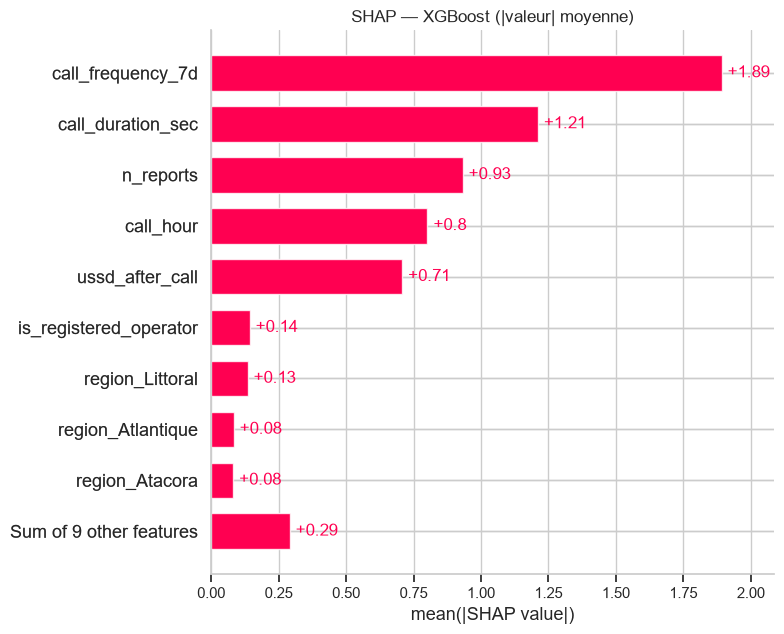

In [19]:
tree_sv = shap.TreeExplainer(best["XGBoost"])(X_te[:500]); tree_sv.feature_names = NAMES
shap.plots.bar(tree_sv, max_display=10, show=False); plt.title("SHAP — XGBoost (|valeur| moyenne)")
plt.tight_layout(); plt.savefig(FIG / "12_shap_xgb.png", dpi=120, bbox_inches="tight"); plt.show()

### 6.3 Une décision expliquée : pourquoi cet appel est-il jugé frauduleux ?

call_hour                     12
call_duration_sec             58
n_reports                     30
call_frequency_7d              4
is_registered_operator     False
region                    Borgou
ussd_after_call            False
risk                         1.0
Name: 4724, dtype: object


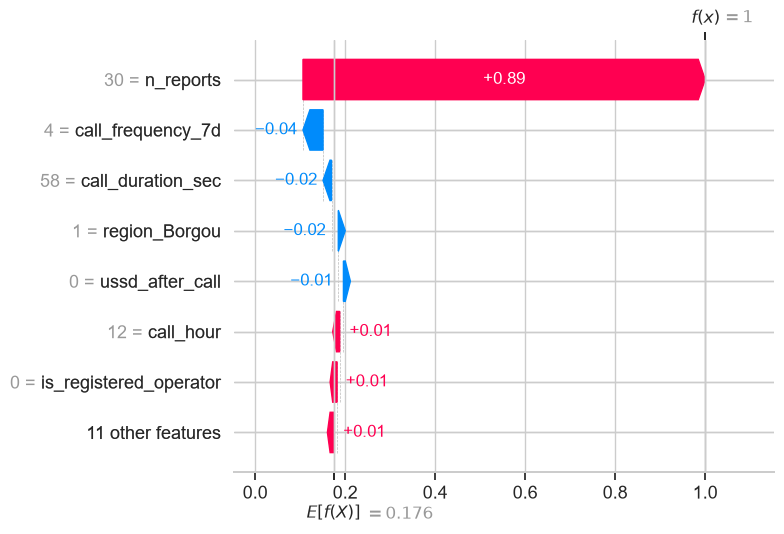

In [20]:
p_te = proba_te["MLP (Keras)"]; t_mlp = thr["MLP (Keras)"]
te = df.iloc[i_te].assign(risk=p_te, pred=(p_te >= t_mlp))
tp_i = int(np.argmax(np.where(te.is_fraud & te.pred, te.risk, -1)))
one = explainer(X_te[tp_i:tp_i + 1])
print(te.iloc[tp_i][["call_hour", "call_duration_sec", "n_reports", "call_frequency_7d", "is_registered_operator", "region", "ussd_after_call", "risk"]])
shap.plots.waterfall(one[0], max_display=8, show=False)
plt.tight_layout(); plt.savefig(FIG / "13_shap_waterfall.png", dpi=120, bbox_inches="tight"); plt.show()

### 6.4 Succès et échecs : analyse des erreurs

In [21]:
cols = ["call_hour", "call_duration_sec", "n_reports", "call_frequency_7d", "is_registered_operator", "region", "ussd_after_call", "risk"]
fn = te[te.is_fraud & ~te.pred]; fp = te[~te.is_fraud & te.pred]
print(f"Faux négatifs (fraudes ratées) : {len(fn)} — dont {(fn.n_reports == 0).mean():.0%} avec 0 signalement, "
      f"{(fn.call_frequency_7d < 50).mean():.0%} avec < 50 appels/7j, {fn.ussd_after_call.mean():.0%} avec USSD")
print(f"Faux positifs (fausses alertes) : {len(fp)} — dont {(fp.call_frequency_7d >= 40).mean():.0%} gros appelants (commerçants), "
      f"{(fp.n_reports > 0).mean():.0%} avec un faux signalement, {fp.ussd_after_call.mean():.0%} avec USSD")
display(fn[cols].head(5)); display(fp[cols].head(5))

Faux négatifs (fraudes ratées) : 21 — dont 95% avec 0 signalement, 71% avec < 50 appels/7j, 10% avec USSD
Faux positifs (fausses alertes) : 60 — dont 65% gros appelants (commerçants), 10% avec un faux signalement, 35% avec USSD


,call_hour,call_duration_sec,n_reports,call_frequency_7d,is_registered_operator,region,ussd_after_call,risk
1313,8,261,0,10,False,Oueme,False,0.216672
9664,12,34,0,34,False,Atlantique,False,0.304589
6208,10,45,0,99,False,Borgou,False,0.535445
5323,8,108,0,73,False,Mono,False,0.468182
7265,16,260,0,23,False,Atlantique,False,0.462567


,call_hour,call_duration_sec,n_reports,call_frequency_7d,is_registered_operator,region,ussd_after_call,risk
2914,10,67,0,45,False,Littoral,False,0.713075
385,13,151,0,83,False,Zou,False,0.700556
5888,15,150,0,83,False,Zou,True,0.982372
4244,9,117,0,73,False,Borgou,False,0.894331
8276,16,467,0,101,False,Oueme,True,0.817332


**Lecture.** Les fraudes ratées sont typiquement des **numéros neufs** (aucun signalement) qui appellent **peu**
(fraudeur « prudent ») — exactement le profil que la base communautaire ne peut pas encore connaître. C'est
pourquoi l'app combine le modèle avec la **couche 2** (interception USSD) : même un fraudeur indétectable à
l'appel est arrêté au moment où la victime tape le code de transfert. Les fausses alertes viennent surtout des
**commerçants** qui appellent beaucoup, et des **faux signalements** — d'où la règle « 3 signalements de
3 utilisateurs différents » côté backend.

## 7. Export TensorFlow Lite pour l'application Android

L'app a besoin de **deux** modèles, car toutes les features n'existent pas au même moment :

| Modèle | Quand | Features | Usage dans l'app |
|---|---|---|---|
| `bamm_precall.tflite` | le téléphone **sonne** | heure, signalements, fréquence 7 j, whitelist, région | écran rouge **avant** de décrocher |
| `bamm_full.tflite` | l'appel est **terminé** / un USSD est tapé | les 8 features | confirmation, blocage USSD, invitation à signaler |

Utiliser le modèle complet à la sonnerie serait une **fuite d'information** (la durée et l'USSD ne sont pas
encore connus) : on entraîne donc un modèle dédié, avec la même méthodologie, et on mesure honnêtement sa perte
de performance.

In [22]:
P = F.PRECALL; NAMES_P = F.feature_names(P)
Xp = F.encode(df, P); Xp_tr, Xp_va, Xp_te = Xp[i_tr], Xp[i_va], Xp[i_te]
mp, vp = F.scaler_stats(Xp_tr, P)
mlp_pre = M.build_mlp(Xp.shape[1], mp, vp, dropout=bd, lr=blr)
M.fit_mlp(mlp_pre, Xp_tr, y_tr, Xp_va, y_va)
thr_pre = best_threshold(y_va, mlp_pre.predict(Xp_va, verbose=0).ravel())
pp = mlp_pre.predict(Xp_te, verbose=0).ravel(); yh = (pp >= thr_pre).astype(int)
pre_metrics = {"seuil": thr_pre, "Precision": precision_score(y_te, yh), "Recall": recall_score(y_te, yh),
               "F1": f1_score(y_te, yh), "AUC-ROC": roc_auc_score(y_te, pp)}
pd.DataFrame({"complet (après appel)": results.loc["MLP (Keras)", list(pre_metrics)], "avant décroché": pre_metrics}).round(3)

,complet (après appel),avant décroché
seuil,0.640,0.490
Precision,0.773,0.557
Recall,0.907,0.911
F1,0.834,0.691
AUC-ROC,0.981,0.954


In [23]:
exports = {}
for key, model, Xte, names, spec, t in [("full", mlp, X_te, NAMES, F.FULL, thr["MLP (Keras)"]),
                                        ("precall", mlp_pre, Xp_te, NAMES_P, F.PRECALL, thr_pre)]:
    blob = M.to_tflite(model)
    path = MODELS / f"bamm_{key}.tflite"; path.write_bytes(blob)
    p_keras = model.predict(Xte, verbose=0).ravel(); p_lite = M.tflite_predict(blob, Xte)
    agree = ((p_keras >= t) == (p_lite >= t)).mean()
    print(f"{path.name}: {len(blob)/1024:.1f} Ko | écart max Keras/TFLite = {np.abs(p_keras - p_lite).max():.4f} | décisions identiques : {agree:.2%}")
    exports[key] = {"file": path.name, "features": names, "numeric": spec["numeric"], "boolean": spec["boolean"],
                    "threshold": round(t, 3), "size_kb": round(len(blob) / 1024, 1)}

Saved artifact at 'C:\Users\HPELIT~1\AppData\Local\Temp\tmplcblhu0p'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 18), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1782608943760: TensorSpec(shape=(1, 18), dtype=tf.float32, name=None)
  1782608952784: TensorSpec(shape=(1, 18), dtype=tf.float32, name=None)
  1782608952016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782608950480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782608952976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782608942800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782608940304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782608952400: TensorSpec(shape=(), dtype=tf.resource, name=None)


bamm_full.tflite: 7.4 Ko | écart max Keras/TFLite = 0.0000 | décisions identiques : 100.00%


Saved artifact at 'C:\Users\HPELIT~1\AppData\Local\Temp\tmpc0lje736'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 16), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1782679325968: TensorSpec(shape=(1, 16), dtype=tf.float32, name=None)
  1782679326544: TensorSpec(shape=(1, 16), dtype=tf.float32, name=None)
  1784365316816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782630547728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782679322704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782679338640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782679333072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1782679336912: TensorSpec(shape=(), dtype=tf.resource, name=None)


bamm_precall.tflite: 7.1 Ko | écart max Keras/TFLite = 0.0000 | décisions identiques : 100.00%


In [24]:
meta = {
    "version": time.strftime("%Y-%m-%d"),
    "regions": dataset.REGIONS,
    "models": exports,
    "alert_levels": {"red": "risk >= threshold", "orange": "risk >= threshold / 2 ou numéro inconnu"},
    "community_red_threshold": 3,
    "test_metrics": {"full": results.loc["MLP (Keras)"].to_dict(), "precall": pre_metrics},
}
meta = json.loads(json.dumps(meta, default=float))
(MODELS / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

# Copie dans les assets de l'app Android : le modèle de l'app est celui de ce notebook.
assets = Path("../../android/app/src/main/assets")
if assets.exists():
    import shutil
    for f in ["bamm_full.tflite", "bamm_precall.tflite", "model_meta.json"]:
        shutil.copy(MODELS / f, assets / f)
    print("Copié dans", assets.resolve())
print(json.dumps({k: {kk: v[kk] for kk in ("file", "threshold", "size_kb")} for k, v in exports.items()}, indent=1))

Copié dans C:\Users\HP ELITEBOOK 850 G6\Desktop\Projet BAAM\android\app\src\main\assets
{
 "full": {
  "file": "bamm_full.tflite",
  "threshold": 0.64,
  "size_kb": 7.4
 },
 "precall": {
  "file": "bamm_precall.tflite",
  "threshold": 0.49,
  "size_kb": 7.1
 }
}


## 8. Limites et pistes d'amélioration

**Limites**
- **Dataset synthétique** : les distributions sont calibrées sur des rapports publics, pas sur des journaux d'appels
  réels. Les performances mesurées ici valident la *méthode*, pas la performance terrain.
- **Biais régional** : la région influence légèrement le score ; un utilisateur du Littoral reçoit un risque un peu
  plus élevé à profil égal. À auditer sur données réelles, voire à retirer si l'effet n'est pas confirmé.
- **Évolution des fraudeurs** : numéros jetables, appels plus rares pour échapper à `call_frequency_7d` → dérive
  du modèle. La couche USSD (règles déterministes) reste efficace même dans ce cas.
- **Fréquence d'appels côté téléphone** : l'app ne voit pas les appels passés aux *autres* utilisateurs ; elle
  l'estime via le backend communautaire (nombre de vérifications distinctes du numéro sur 7 jours).
- **Faux signalements / attaques de la base** : atténués par le seuil de 3 signalements d'utilisateurs distincts.
- **Permissions Android** : filtrage d'appels (rôle `CallScreeningService`), accessibilité et superposition doivent
  être accordés par l'utilisateur.

**Pistes**
- Partenariat MTN/Moov Bénin pour des métadonnées anonymisées réelles et une whitelist officielle à jour ;
- apprentissage en ligne / ré-entraînement périodique avec les signalements validés ;
- calibration des probabilités (Platt / isotonic) et suivi de la dérive ;
- extension régionale (MTN MoMo Ghana, M-Pesa Kenya) avec la même architecture.